# EDA: German Credit (credit-g)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../feature_store/credit_features.csv')

## 1. First look

In [3]:
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,risk,credit_per_month
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,67,none,own,2,skilled,1,yes,yes,0,194.833333
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,22,none,own,1,skilled,1,none,yes,1,123.979167
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,49,none,own,1,unskilled resident,2,none,yes,0,174.666667
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,45,none,for free,1,skilled,2,none,yes,0,187.666667
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,53,none,for free,2,skilled,2,none,yes,1,202.916667


In [4]:
df.tail()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,risk,credit_per_month
995,no checking,12,existing paid,furniture/equipment,1736,<100,4<=X<7,3,female div/dep/mar,none,...,31,none,own,1,unskilled resident,1,none,yes,0,144.666667
996,<0,30,existing paid,used car,3857,<100,1<=X<4,4,male div/sep,none,...,40,none,own,1,high qualif/self emp/mgmt,1,yes,yes,0,128.566667
997,no checking,12,existing paid,radio/tv,804,<100,>=7,4,male single,none,...,38,none,own,1,skilled,1,none,yes,0,67.000000
998,<0,45,existing paid,radio/tv,1845,<100,1<=X<4,4,male single,none,...,23,none,for free,1,skilled,1,yes,yes,1,41.000000
999,0<=X<200,45,critical/other existing credit,used car,4576,100<=X<500,unemployed,3,male single,none,...,27,none,own,1,skilled,1,none,yes,0,101.688889


In [5]:
df.shape

(1000, 22)

In [6]:
df.columns

Index(['checking_status', 'duration', 'credit_history', 'purpose',
       'credit_amount', 'savings_status', 'employment',
       'installment_commitment', 'personal_status', 'other_parties',
       'residence_since', 'property_magnitude', 'age', 'other_payment_plans',
       'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone',
       'foreign_worker', 'risk', 'credit_per_month'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   checking_status         1000 non-null   str    
 1   duration                1000 non-null   int64  
 2   credit_history          1000 non-null   str    
 3   purpose                 1000 non-null   str    
 4   credit_amount           1000 non-null   int64  
 5   savings_status          1000 non-null   str    
 6   employment              1000 non-null   str    
 7   installment_commitment  1000 non-null   int64  
 8   personal_status         1000 non-null   str    
 9   other_parties           1000 non-null   str    
 10  residence_since         1000 non-null   int64  
 11  property_magnitude      1000 non-null   str    
 12  age                     1000 non-null   int64  
 13  other_payment_plans     1000 non-null   str    
 14  housing                 1000 non-null   str    
 15 

In [8]:
df.dtypes.value_counts()

str        13
int64       8
float64     1
Name: count, dtype: int64

## 2. Data quality

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.nunique()

checking_status             4
duration                   33
credit_history              5
purpose                    10
credit_amount             921
savings_status              5
employment                  5
installment_commitment      4
personal_status             4
other_parties               3
residence_since             4
property_magnitude          4
age                        53
other_payment_plans         3
housing                     3
existing_credits            4
job                         4
num_dependents              2
own_telephone               2
foreign_worker              2
risk                        2
credit_per_month          965
dtype: int64

## 3. Summary statistics

In [12]:
df.describe()

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents,risk,credit_per_month
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,0.300000,167.687020
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487,153.490959
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,0.000000,24.055556
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,0.000000,89.600000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,0.000000,130.333333
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,1.000000,206.183333
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,1.000000,2482.666667


In [13]:
df.describe(include='object')

C:\Users\gaura\AppData\Local\Temp\ipykernel_8804\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,checking_status,credit_history,purpose,savings_status,employment,personal_status,other_parties,property_magnitude,other_payment_plans,housing,job,own_telephone,foreign_worker
count,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
unique,4,5,10,5,5,4,3,4,3,3,4,2,2
top,no checking,existing paid,radio/tv,<100,1<=X<4,male single,none,car,none,own,skilled,none,yes
freq,394,530,280,603,339,548,907,332,814,713,630,596,963


## 4. Target distribution (1 = bad risk)

In [14]:
df['risk'].value_counts()

risk
0    700
1    300
Name: count, dtype: int64

In [15]:
df['risk'].value_counts(normalize=True)

risk
0    0.7
1    0.3
Name: proportion, dtype: float64

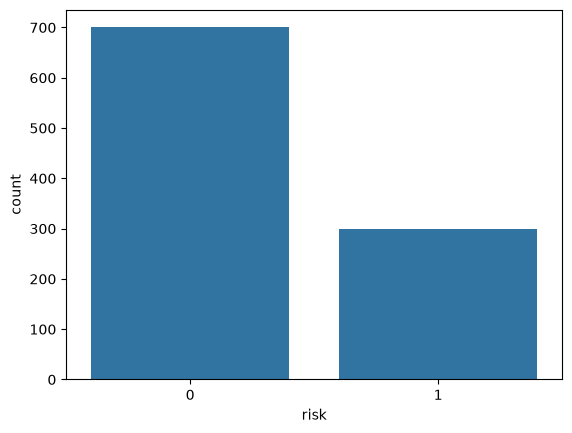

In [16]:
sns.countplot(x='risk', data=df)
plt.show()

## 5. Numeric features

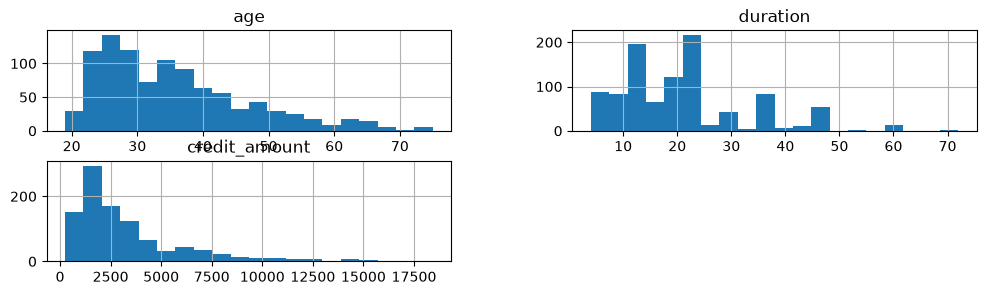

In [17]:
df[['age', 'duration', 'credit_amount']].hist(bins=20, figsize=(12, 3))
plt.show()

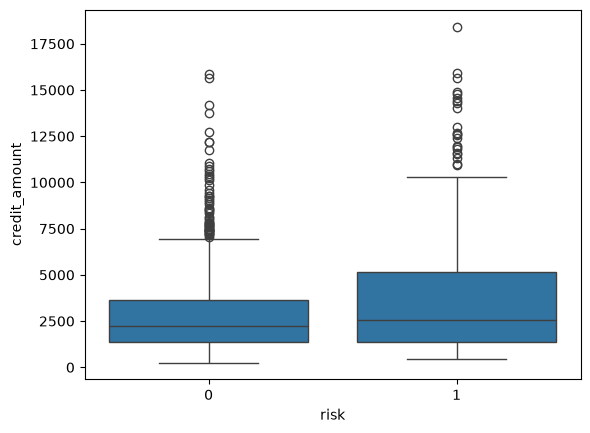

In [18]:
sns.boxplot(x='risk', y='credit_amount', data=df)
plt.show()

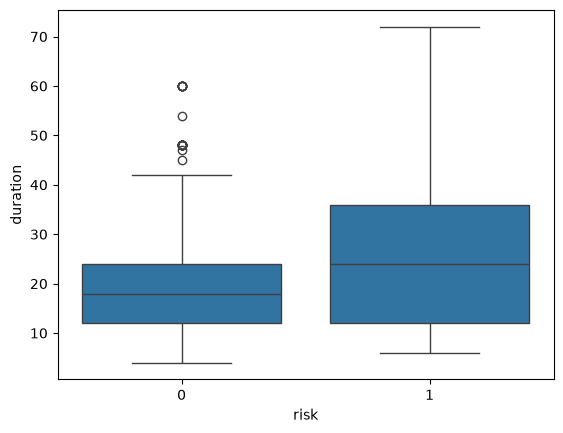

In [19]:
sns.boxplot(x='risk', y='duration', data=df)
plt.show()

## 6. Categorical features vs risk

In [20]:
df.groupby('checking_status')['risk'].mean().sort_values()

checking_status
no checking    0.116751
>=200          0.222222
0<=X<200       0.390335
<0             0.492701
Name: risk, dtype: float64

In [21]:
df.groupby('purpose')['risk'].mean().sort_values()

purpose
retraining             0.111111
used car               0.165049
radio/tv               0.221429
furniture/equipment    0.320442
domestic appliance     0.333333
business               0.350515
repairs                0.363636
new car                0.380342
other                  0.416667
education              0.440000
Name: risk, dtype: float64

In [22]:
pd.crosstab(df['housing'], df['risk'], normalize='index')

risk,0,1
housing,,
for free,0.592593,0.407407
own,0.739130,0.260870
rent,0.608939,0.391061


## 7. Correlation

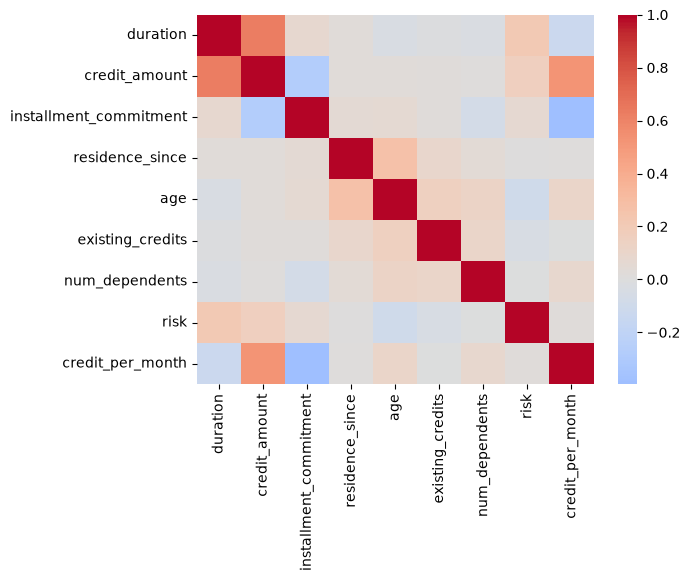

In [23]:
corr = df.select_dtypes('number').corr()
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.show()

In [24]:
corr['risk'].sort_values()

age                      -0.091127
existing_credits         -0.045732
num_dependents           -0.003015
residence_since           0.002967
credit_per_month          0.018592
installment_commitment    0.072404
credit_amount             0.154739
duration                  0.214927
risk                      1.000000
Name: risk, dtype: float64